# Exploring the Dash *et al* dataset

This data was generated in [Quantifiable predictive features define epitope specific T cell  receptor repertoires](https://doi.org/10.1038/nature22383) and further analysed in [Measures of epitope binding degeneracy from T cell receptor repertoires](https://www.pnas.org/doi/abs/10.1073/pnas.2213264120). In this notebook we explore the dataset and re-create some of the analysis done in other works.

In [1]:
import anarci
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tidytcells
import umap
from matplotlib.axes import Axes
from pyxdameraulevenshtein import damerau_levenshtein_distance
from sklearn.cluster import HDBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

from tcr_pmhc_predicted_structures.imgt_numbering import IMGT_CDR3

2026-01-26 15:32:18.991737: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
CLIP_DISTANCE = 5
MIN_CLUSTER_SIZE = 3

In [3]:
def plot_umap(umap: np.ndarray, clusters: np.ndarray, title: str | None = None, ax: Axes | None = None) -> Axes:
    clusters = clusters.copy()
    clusters[(clusters != 'None') & (clusters != 'Background')] = (
        'Cluster ' + clusters[(clusters != 'None') & (clusters != 'Background')]
    )

    ax = sns.scatterplot(
        x=umap[(clusters != 'None') & (clusters != 'Background'), 0],
        y=umap[(clusters != 'None') & (clusters != 'Background'), 1],
        hue=clusters[(clusters != 'None') & (clusters != 'Background')],
        alpha=0.65,
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'None', 0],
        y=umap[clusters == 'None', 1],
        color='grey',
        alpha=0.55,
        label='None',
        ax=ax,
    )

    ax = sns.scatterplot(
        x=umap[clusters == 'Background', 0],
        y=umap[clusters == 'Background', 1],
        marker='x',
        color='black',
        alpha=0.55,
        label='Background',
        ax=ax,
    )

    ax.set_title(title)
    ax.legend(title='Cluster')

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')

    ax.set_xticklabels([])
    ax.set_yticklabels([])

    return ax

In [4]:
dash = pd.read_csv('../data/external/dash_human.csv')
dash.index.name = 'id'
dash = dash.reset_index()
dash['id'] = 'dash_' + dash['id'].astype(str)

In [5]:
dash = dash.dropna()

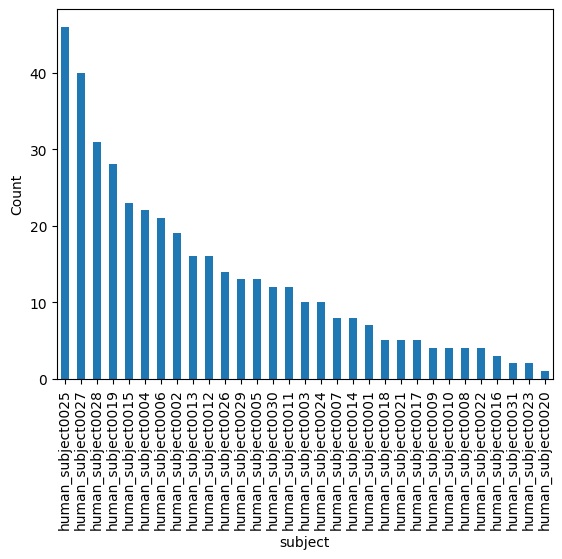

In [6]:
dash['subject'].value_counts().plot.bar()

plt.ylabel('Count')

plt.show()

In [7]:
dash.value_counts('epitope')

epitope
M1      249
BMLF     92
pp65     67
Name: count, dtype: int64

In [8]:
epitope_info = pd.DataFrame(
    columns=['name', 'species', 'mhc', 'peptide_seq', 'virus'],
    data=[
        ['BMLF', 'human', 'HLA-A*02:01', 'GLCTLVAML', 'EBV'],
        ['M1', 'human', 'HLA-A*02:01', 'GILGFVFTL', 'IAV'],
        ['pp65', 'human', 'HLA-A*02:01', 'NLVPMVATV', 'CMV'],
    ],
)

epitope_info.set_index('name')

,species,mhc,peptide_seq,virus
name,,,,
BMLF,human,HLA-A*02:01,GLCTLVAML,EBV
M1,human,HLA-A*02:01,GILGFVFTL,IAV
pp65,human,HLA-A*02:01,NLVPMVATV,CMV


In [9]:
sequences_with_negatives = pd.read_csv('../data/interim/sequences_dash_with_negatives.csv')

sequences_with_negatives = sequences_with_negatives.merge(dash, how='left', on='id')

sequences_with_negatives.loc[sequences_with_negatives['subject'].isna(), 'subject'] = 'Background'
sequences_with_negatives.loc[sequences_with_negatives['epitope'].isna(), 'epitope'] = 'Background'

In [10]:
def get_cdr3(sequence: str) -> str:
    numbering, _ = anarci.number(sequence)
    cdr3 = ''.join(amino_acid for (seq_id, _), amino_acid in numbering if amino_acid != '-' and seq_id in IMGT_CDR3)
    return tidytcells.junction.standardise(cdr3)


sequences_with_negatives['cdr3_alpha'] = sequences_with_negatives['tcr_alpha_chain'].apply(get_cdr3)
sequences_with_negatives['cdr3_beta'] = sequences_with_negatives['tcr_beta_chain'].apply(get_cdr3)

In [11]:
sequences_with_negatives = sequences_with_negatives.merge(
    epitope_info[['name', 'mhc', 'peptide_seq', 'virus']], how='left', left_on='peptide', right_on='peptide_seq'
)

In [12]:
num_tcrs = len(sequences_with_negatives)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives.iloc[i]['cdr3_alpha'], sequences_with_negatives.iloc[j]['cdr3_alpha']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives.iloc[i]['cdr3_beta'], sequences_with_negatives.iloc[j]['cdr3_beta']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [13]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [14]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [15]:
clusters_filtered = np.array(
    [str(cluster) if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else 'None' for cluster in clusters]
)

In [16]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [17]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [18]:
unique_subjects = sorted(sequences_with_negatives['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array(
    [[subject_to_colour[subject]] for subject in sequences_with_negatives['subject'].to_numpy()[new_order]]
)

In [19]:
unique_epitopes = sorted(sequences_with_negatives['epitope'].unique())
epitope_to_colour = {epitope: palette[i % num_colours] for i, epitope in enumerate(unique_epitopes)}
epitope_colours = np.array(
    [[epitope_to_colour[epitope]] for epitope in sequences_with_negatives['epitope'].to_numpy()[new_order]]
)

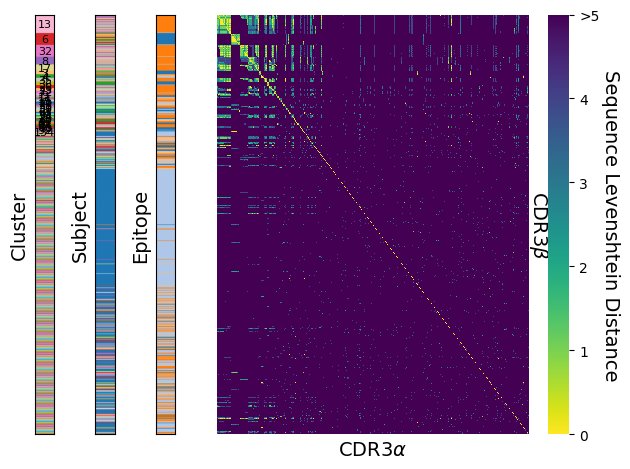

In [20]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, gridspec_kw={'width_ratios': [1, 1, 1, 20]})

ax1.imshow(cluster_colours, aspect='auto')

ax1.set_ylabel('Cluster', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

accumulation = 0
for cluster in cluster_order:
    cluster_size = cluster_counts[cluster]

    if cluster_size >= MIN_CLUSTER_SIZE:
        position = cluster_counts[cluster] // 2 + accumulation
        ax1.text(
            x=0.025,
            y=position,
            s=str(cluster),
            va='center',
            ha='center',
            fontsize=8,
        )

    accumulation += cluster_size

ax2.imshow(subject_colours, aspect='auto')

ax2.set_ylabel('Subject', fontsize=14)
ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

ax3.imshow(epitope_colours, aspect='auto')

ax3.set_ylabel('Epitope', fontsize=14)
ax3.set_xticks([])
ax3.set_xticklabels('')
ax3.set_yticks([])
ax3.set_yticklabels('')

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax4
)

ax4.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax4.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax4.yaxis.set_label_position('right')

ax4.set_xticks([])
ax4.set_xticklabels('')
ax4.set_yticks([])
ax4.set_yticklabels('')

cbar = ax4.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()

In [21]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

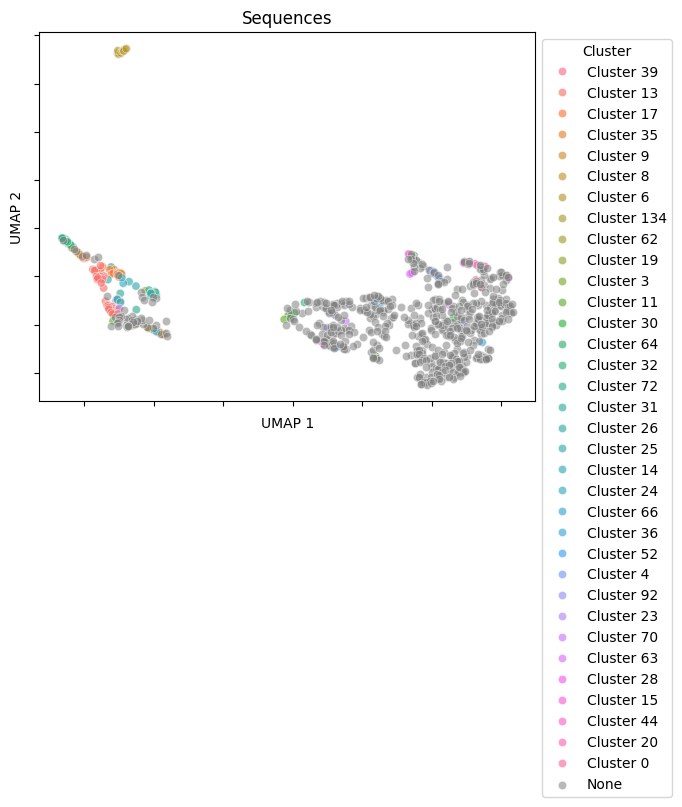

In [22]:
ax = plot_umap(sequence_umap, pd.Series(clusters_filtered), title='Sequences')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))

plt.show()

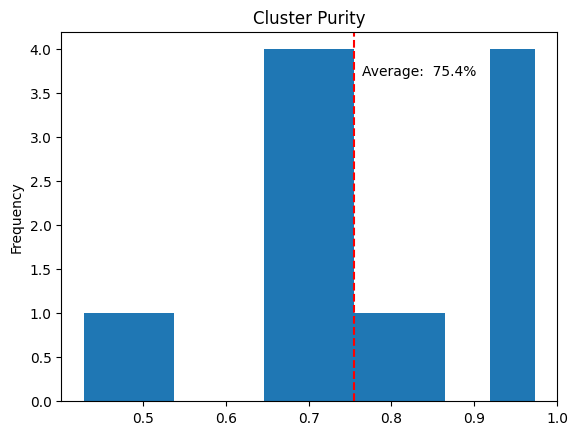

In [23]:
cluster_purities = (
    sequences_with_negatives.groupby(clusters_filtered)['epitope']
    .value_counts(normalize=True)
    .reset_index()
    .groupby('level_0')
    .filter(lambda group: group['epitope'].nunique() > 1 and 'Background' not in group['epitope'])  # noqa: PD101
    .groupby('level_0')
    .agg({'proportion': 'max'})
    .reset_index()
    .query("level_0 != 'None'")
)

cluster_purities['proportion'].plot.hist()

purity_mean = cluster_purities['proportion'].mean()
plt.axvline(purity_mean, color='red', linestyle='dashed')
plt.text(purity_mean + 0.01, plt.ylim()[1] - 0.5, f'Average: {purity_mean * 100: .1f}%')

plt.title('Cluster Purity')

plt.show()

## M1 Epitope Analysis

In [24]:
dash_m1 = dash.query("epitope == 'M1'").copy()

In [25]:
num_tcrs = len(dash_m1)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_a_aa'], dash.iloc[j]['cdr3_a_aa']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_b_aa'], dash.iloc[j]['cdr3_b_aa']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [26]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [27]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [28]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [29]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [30]:
unique_subjects = sorted(dash_m1['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_m1['subject'].to_numpy()[new_order]])

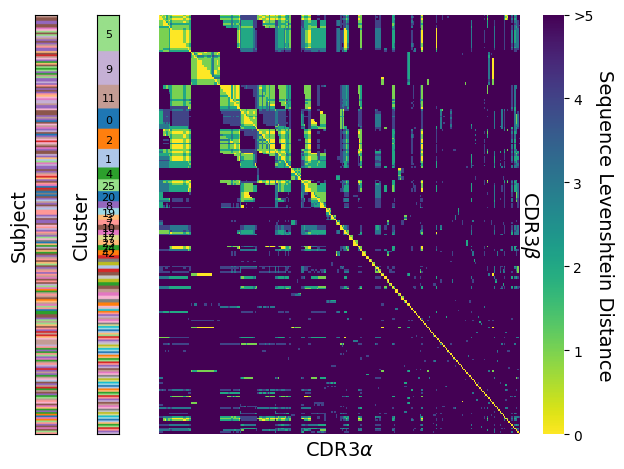

In [31]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

ax1.imshow(subject_colours, aspect='auto')

ax1.set_ylabel('Subject', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

ax2.imshow(cluster_colours, aspect='auto')

ax2.set_ylabel('Cluster', fontsize=14)
ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

accumulation = 0
for cluster in cluster_order:
    cluster_size = cluster_counts[cluster]

    if cluster_size >= MIN_CLUSTER_SIZE:
        position = cluster_counts[cluster] // 2 + accumulation
        ax2.text(
            x=0.025,
            y=position,
            s=str(cluster),
            va='center',
            ha='center',
            fontsize=8,
        )

    accumulation += cluster_size

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax3
)

ax3.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax3.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax3.yaxis.set_label_position('right')

ax3.set_xticks([])
ax3.set_xticklabels('')
ax3.set_yticks([])
ax3.set_yticklabels('')

cbar = ax3.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()

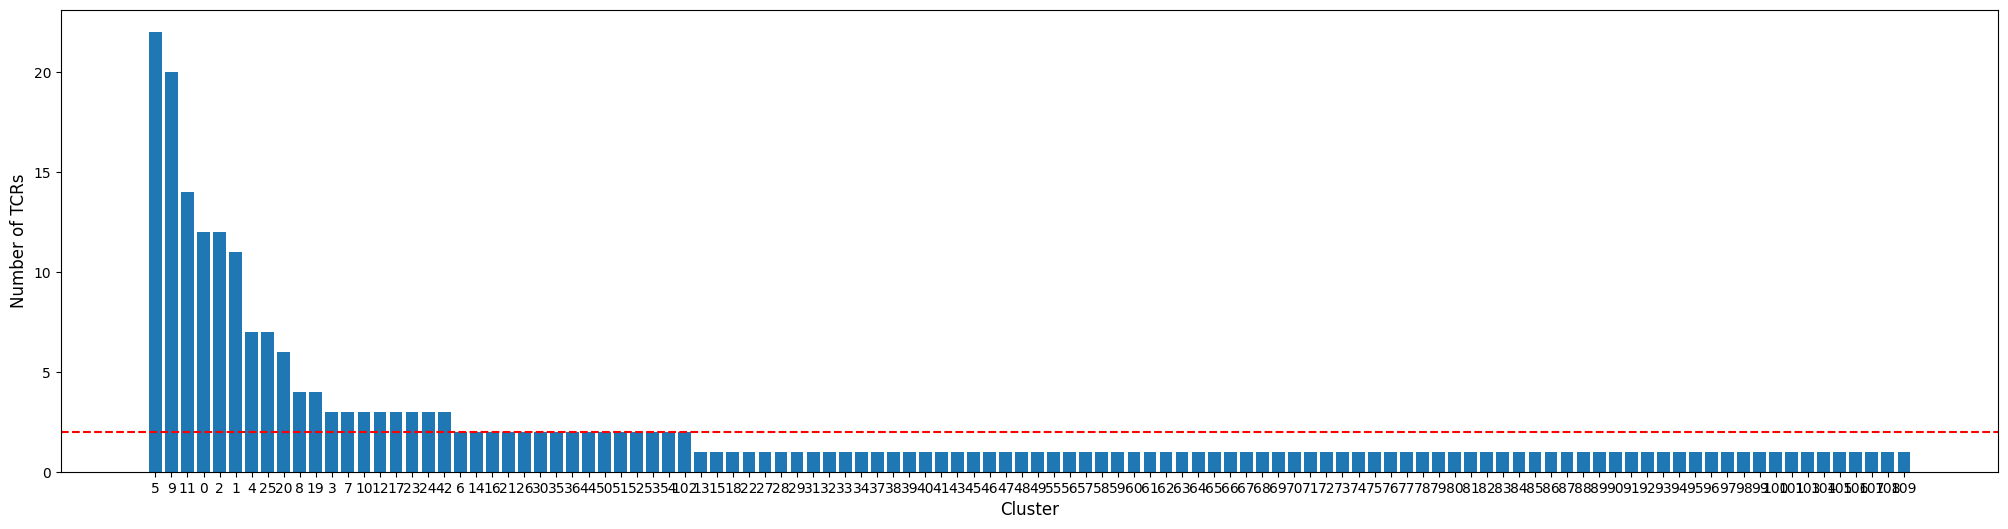

In [32]:
plt.figure(figsize=(25, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(2, color='red', linestyle='--')

plt.show()

In [33]:
clusters_filtered = np.array([cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters])

In [34]:
dash_m1['cluster'] = clusters_filtered
dash_m1['cluster'] = dash_m1['cluster'].astype(str)
dash_m1['cluster'] = dash_m1['cluster'].replace('-1', 'None')

In [35]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

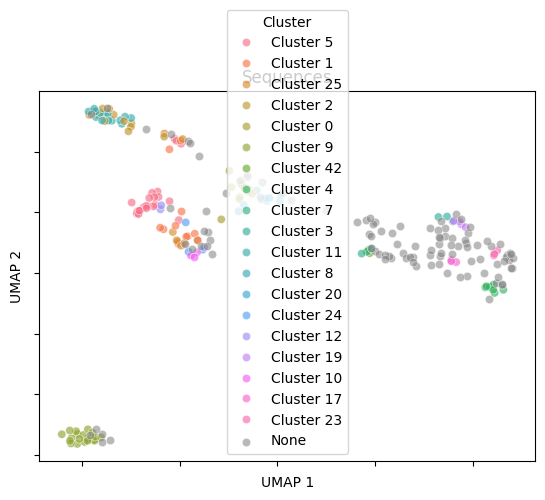

In [36]:
plot_umap(sequence_umap, dash_m1['cluster'], title='Sequences')
plt.show()

In [37]:
sequences_with_negatives_m1 = sequences_with_negatives.query("name == 'M1'")

In [38]:
sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1 = sequences_with_negatives_m1.merge(dash_m1[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_m1['cluster'] = sequences_with_negatives_m1['cluster'].fillna('Background')

In [39]:
num_tcrs = len(sequences_with_negatives_m1)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_m1.iloc[i]['cdr3_alpha'], sequences_with_negatives_m1.iloc[j]['cdr3_alpha']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_m1.iloc[i]['cdr3_beta'], sequences_with_negatives_m1.iloc[j]['cdr3_beta']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [40]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

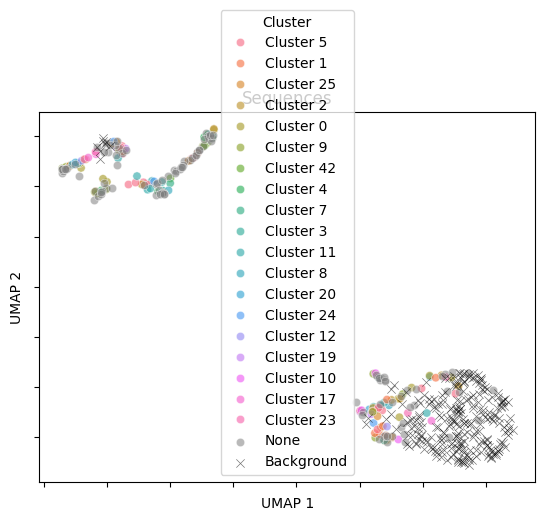

In [41]:
plot_umap(sequence_umap_with_background, sequences_with_negatives_m1['cluster'], title='Sequences')
plt.show()

## BMLF Epitope Analysis

In [42]:
dash_bmlf = dash.query("epitope == 'BMLF'").copy()

In [43]:
num_tcrs = len(dash_bmlf)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_a_aa'], dash.iloc[j]['cdr3_a_aa']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_b_aa'], dash.iloc[j]['cdr3_b_aa']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [44]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [45]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [46]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [47]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [48]:
unique_subjects = sorted(dash_bmlf['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_bmlf['subject'].to_numpy()[new_order]])

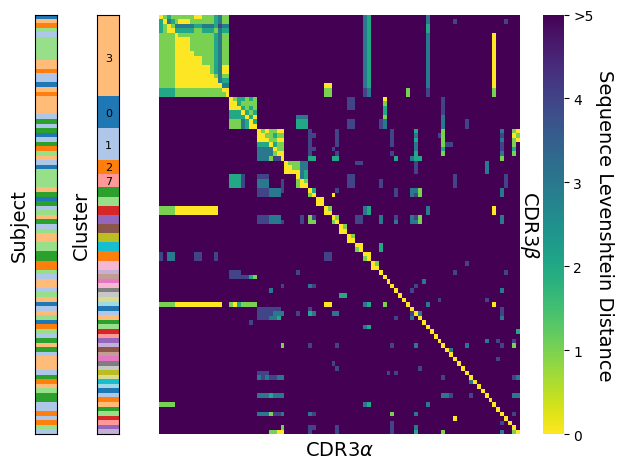

In [49]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

ax1.imshow(subject_colours, aspect='auto')

ax1.set_ylabel('Subject', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

ax2.imshow(cluster_colours, aspect='auto')

ax2.set_ylabel('Cluster', fontsize=14)
ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

accumulation = 0
for cluster in cluster_order:
    cluster_size = cluster_counts[cluster]

    if cluster_size >= MIN_CLUSTER_SIZE:
        position = cluster_counts[cluster] // 2 + accumulation
        ax2.text(
            x=0.025,
            y=position,
            s=str(cluster),
            va='center',
            ha='center',
            fontsize=8,
        )

    accumulation += cluster_size

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax3
)

ax3.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax3.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax3.yaxis.set_label_position('right')

ax3.set_xticks([])
ax3.set_xticklabels('')
ax3.set_yticks([])
ax3.set_yticklabels('')

cbar = ax3.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()

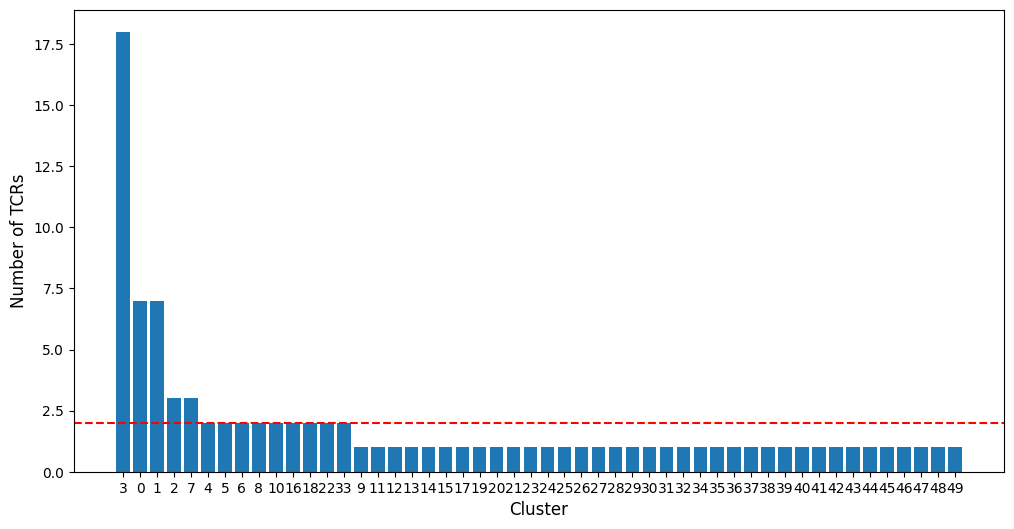

In [50]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(2, color='red', linestyle='--')

plt.show()

In [51]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [52]:
dash_bmlf['cluster'] = clusters_filtered
dash_bmlf['cluster'] = dash_bmlf['cluster'].astype(str)
dash_bmlf['cluster'] = dash_bmlf['cluster'].replace('-1', 'None')

In [53]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

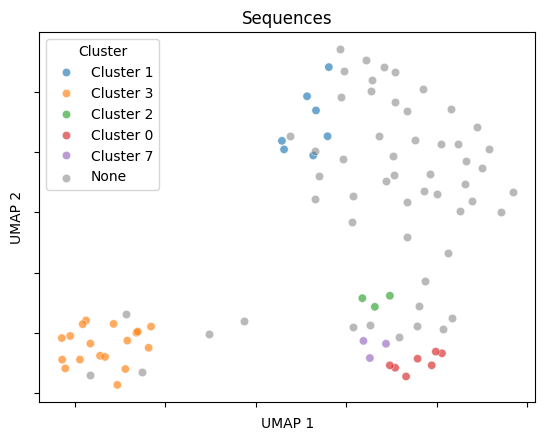

In [54]:
plot_umap(sequence_umap, dash_bmlf['cluster'], title='Sequences')
plt.show()

In [55]:
sequences_with_negatives_bmlf = sequences_with_negatives.query("name == 'BMLF'")

In [56]:
sequences_with_negatives_bmlf.merge(dash_bmlf[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_bmlf = sequences_with_negatives_bmlf.merge(dash_bmlf[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_bmlf['cluster'] = sequences_with_negatives_bmlf['cluster'].fillna('Background')

In [57]:
num_tcrs = len(sequences_with_negatives_bmlf)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_bmlf.iloc[i]['cdr3_alpha'], sequences_with_negatives_bmlf.iloc[j]['cdr3_alpha']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_bmlf.iloc[i]['cdr3_beta'], sequences_with_negatives_bmlf.iloc[j]['cdr3_beta']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [58]:
sequence_umap_with_background = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

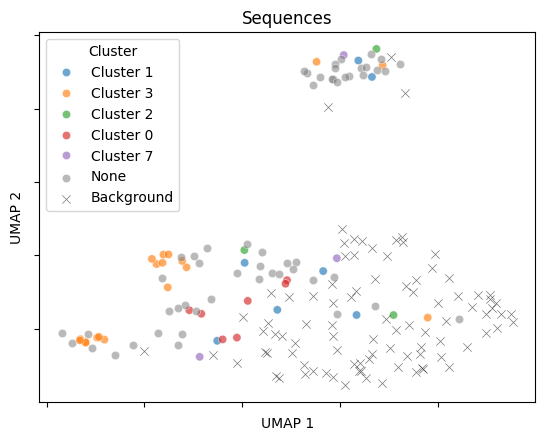

In [59]:
plot_umap(sequence_umap_with_background, sequences_with_negatives_bmlf['cluster'], title='Sequences')
plt.show()

### Structure Prediction Features

In [60]:
def is_constant(column: pd.Series) -> bool:
    return (column == column.iloc[0]).all()


def drop_constant_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    return df[[column_name for column_name in df.columns if not is_constant(df[column_name])]]

#### Confidence Scores

In [61]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_dash_bmlf.csv')
confidence_scores['top_rank'] = False
confidence_scores.loc[confidence_scores.groupby('name')['ranking_score'].idxmax(), 'top_rank'] = True

In [62]:
confidence_scores = confidence_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [63]:
confidence_scores = confidence_scores.merge(dash_bmlf, how='left', left_on='name', right_on='id')
confidence_scores['cluster'] = confidence_scores['cluster'].fillna('Background')

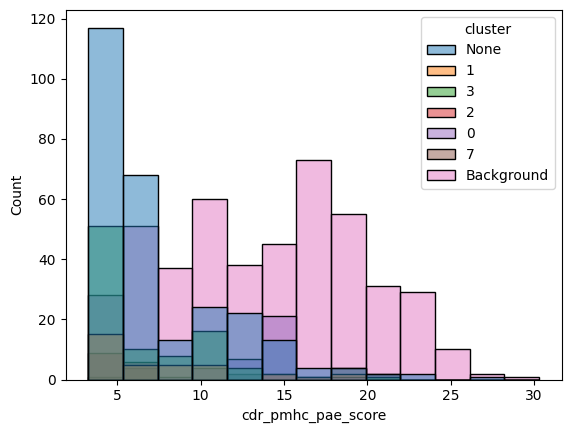

In [64]:
sns.histplot(confidence_scores, x='cdr_pmhc_pae_score', hue='cluster')

plt.show()

In [65]:
confidence_scores_values = confidence_scores.select_dtypes('number')
confidence_scores_values = confidence_scores_values[
    [column_name for column_name in confidence_scores_values.columns if column_name not in ('count', 'sample', 'seed')]
]

confidence_scores_values = drop_constant_columns(confidence_scores_values)
confidence_scores_values = confidence_scores_values.to_numpy()

In [66]:
confidence_scores_values_norm = StandardScaler().fit_transform(confidence_scores_values)
confidence_scores_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(confidence_scores_values_norm)

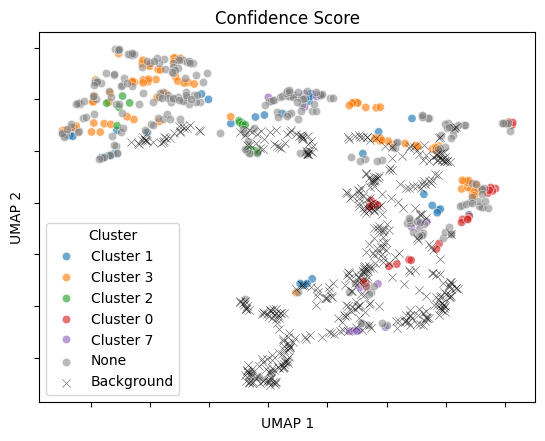

In [67]:
plot_umap(confidence_scores_umap, confidence_scores['cluster'].to_numpy(), title='Confidence Score')
plt.show()

#### Structural Features

In [68]:
structure_features = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_structural_features_dash_bmlf.csv')

In [69]:
structure_features = structure_features.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [70]:
structure_features = structure_features.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
structure_features['cluster'] = structure_features['cluster'].fillna('Background')

In [71]:
structure_features_values = structure_features.select_dtypes('number')
structure_features_values = structure_features_values[
    [
        column_name
        for column_name in structure_features_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]

structure_features_values = drop_constant_columns(structure_features_values)
structure_features_values = structure_features_values.dropna()

selected_stucture_features = structure_features_values.index

structure_features_values = structure_features_values.to_numpy()

In [72]:
structure_features_values_norm = StandardScaler().fit_transform(structure_features_values)
structure_features_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(structure_features_values_norm)

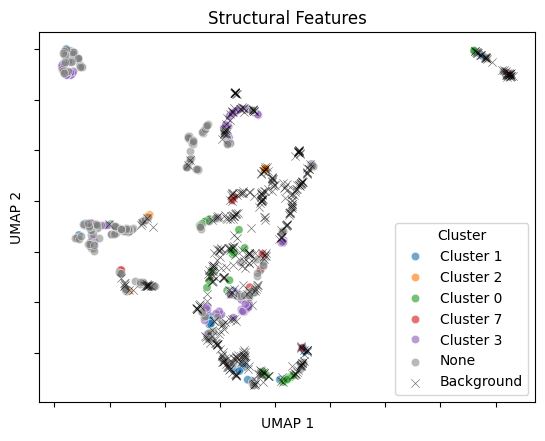

In [73]:
plot_umap(
    structure_features_umap,
    structure_features.loc[selected_stucture_features, 'cluster'].to_numpy(),
    title='Structural Features',
)
plt.show()

##### Contact Maps

In [74]:
contact_maps = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_contact_maps_dash_bmlf.csv')

In [75]:
contact_maps['relative_pos_centre_tcr'] = contact_maps['relative_pos_centre_tcr'].astype(int)

In [76]:
contact_maps['resi_pmhc'] = contact_maps['resi_pmhc'].astype(str).str.replace('.0', '')

In [77]:
contact_maps['chain_type_pmhc'].unique()

array(['antigen_chain', 'mhc_chain1'], dtype=object)

In [78]:
contact_maps_antigens = contact_maps[contact_maps['chain_type_pmhc'] == 'antigen_chain'].copy()

In [79]:
contact_maps_antigens['relative_pos_centre_pmhc'] = contact_maps_antigens['relative_pos_centre_pmhc'].astype(int)

In [80]:
contact_map_antigens_scores = (
    contact_maps_antigens.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'relative_pos_centre_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)
contact_map_antigens_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_antigens_scores.columns.to_flat_index()
]

In [81]:
contact_maps_mhc = contact_maps[contact_maps['chain_type_pmhc'] == 'mhc_chain1'].copy()

In [82]:
contact_map_mhc_scores = (
    contact_maps_mhc.groupby(['name', 'seed', 'sample'])
    .value_counts(['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'])
    .reset_index()
    .pivot_table(
        index=['name', 'seed', 'sample'],
        columns=['cdr_type', 'relative_pos_centre_tcr', 'resi_pmhc'],
        values='count',
    )
    .fillna(0)
    .map(int)
)

contact_map_mhc_scores.columns = [
    '_'.join(str(idx) for idx in indices) for indices in contact_map_mhc_scores.columns.to_flat_index()
]

In [83]:
contact_map_scores = pd.concat([contact_map_antigens_scores, contact_map_mhc_scores], axis=1).fillna(0).map(int)
contact_map_scores = drop_constant_columns(contact_map_scores)
contact_map_column_names = contact_map_scores.columns

contact_map_scores = contact_map_scores.reset_index()

In [84]:
contact_map_scores = contact_map_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [85]:
contact_map_scores = contact_map_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
contact_map_scores['cluster'] = contact_map_scores['cluster'].fillna('Background')

In [86]:
contact_map_scores_norm = StandardScaler().fit_transform(contact_map_scores[contact_map_column_names])

In [87]:
contact_map_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(contact_map_scores_norm)

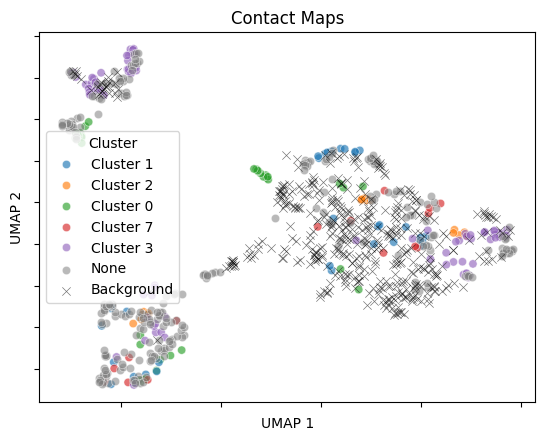

In [88]:
plot_umap(contact_map_umap, contact_map_scores['cluster'].to_numpy(), title='Contact Maps')
plt.show()

##### Interactions

In [89]:
interactions = pd.read_csv('../data/processed/predicted_af3_af3_tcrmodel2_interactions_dash_bmlf.csv')

In [90]:
interactions_scores = (
    interactions.groupby(['name', 'seed', 'sample'])['type']
    .value_counts()
    .reset_index()
    .pivot_table(index=['name', 'seed', 'sample'], columns='type', values='count')
    .fillna(0)
    .map(int)
)
interactions_scores_column_names = interactions_scores.columns

interactions_scores = interactions_scores.reset_index()

In [91]:
interactions_scores = interactions_scores.merge(
    sequences_with_negatives[['id', 'label']], how='left', left_on='name', right_on='id'
)

In [92]:
interactions_scores = interactions_scores.merge(dash_bmlf, how='outer', left_on='name', right_on='id')
interactions_scores['cluster'] = interactions_scores['cluster'].fillna('Background')
interactions_scores[interactions_scores_column_names] = interactions_scores[interactions_scores_column_names].fillna(0)

In [93]:
interactions_scores_norm = StandardScaler().fit_transform(interactions_scores[interactions_scores_column_names])

In [94]:
interactions_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(interactions_scores_norm)

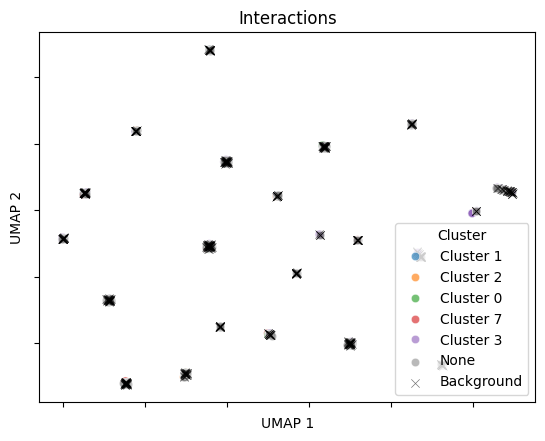

In [95]:
plot_umap(interactions_umap, interactions_scores['cluster'].to_numpy(), title='Interactions')
plt.show()

##### Combined

In [96]:
combined_scores = (
    structure_features.merge(contact_map_scores, how='inner').merge(interactions_scores, how='inner').fillna(0.0)
)

In [97]:
combined_scores_values = combined_scores.select_dtypes('number')
combined_scores_values = combined_scores_values[
    [
        column_name
        for column_name in combined_scores_values.columns
        if column_name not in ('count', 'sample', 'seed', 'label')
    ]
]
combined_scores_values = combined_scores_values.to_numpy()

In [98]:
combined_scores_values_norm = StandardScaler().fit_transform(combined_scores_values)

In [99]:
combined_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(combined_scores_values_norm)

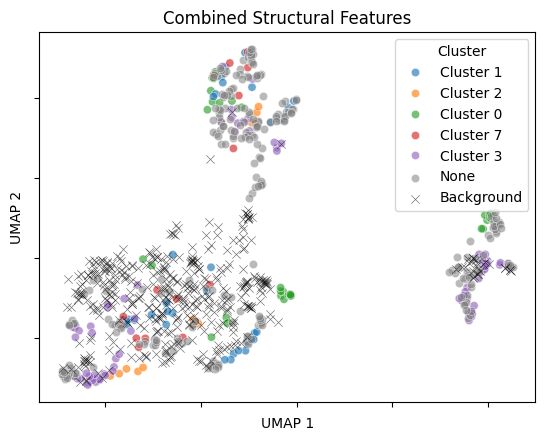

In [100]:
plot_umap(combined_umap, combined_scores['cluster'].to_numpy(), title='Combined Structural Features')
plt.show()

Reversing the structural clusters to the sequence space

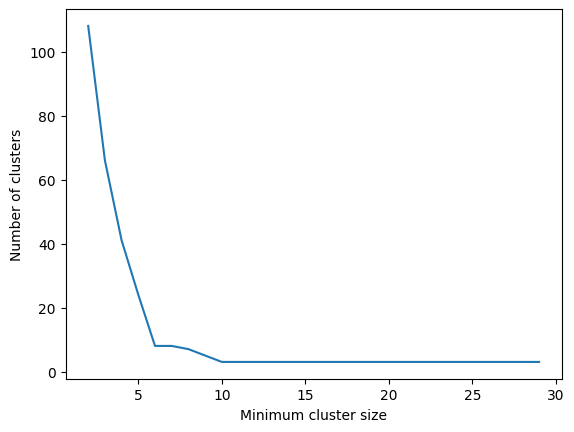

In [101]:
min_cluster_sizes = list(range(2, 30))
num_clusters = []
for min_cluster_size in min_cluster_sizes:
    structural_clusters = HDBSCAN(min_cluster_size=min_cluster_size).fit_predict(
        combined_scores_values_norm[combined_scores['label'].astype(bool)]
    )
    num_clusters.append(len(np.unique(structural_clusters[structural_clusters != -1])))

plt.plot(min_cluster_sizes, num_clusters)

plt.xlabel('Minimum cluster size')
plt.ylabel('Number of clusters')

plt.show()

In [102]:
structural_clusters = (
    HDBSCAN(min_cluster_size=6)
    .fit_predict(combined_scores_values_norm[combined_scores['label'].astype(bool)])
    .astype(str)
)
structural_clusters[structural_clusters == '-1'] = 'None'

combined_scores['structural_cluster'] = 'Background'
combined_scores.loc[combined_scores['label'].astype(bool), 'structural_cluster'] = structural_clusters

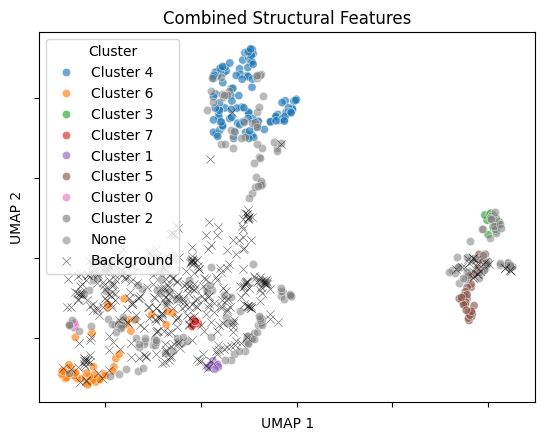

In [103]:
plot_umap(combined_umap, combined_scores['structural_cluster'].to_numpy(), title='Combined Structural Features')
plt.show()

In [104]:
agg_structural_clusters = (
    combined_scores[combined_scores['label'].astype(bool)].groupby('name')['structural_cluster'].apply(list)
)

In [105]:
def count_clusters(clusters: list) -> dict[str, int]:
    count = {}
    for cluster in clusters:
        if cluster not in count:
            count[cluster] = 1

        else:
            count[cluster] += 1

    return count


agg_structural_clusters = agg_structural_clusters.apply(count_clusters)

In [106]:
def get_consensus(cluster_counts: dict) -> str:
    """Get the consensus clustuer from the counts.

    Note: does not handle ties.

    """
    max_count = 0
    consensus_cluster = None

    for cluster, count in cluster_counts.items():
        if count > max_count:
            consensus_cluster = cluster
            max_count = count

    return consensus_cluster


agg_structural_clusters = agg_structural_clusters.apply(get_consensus)

In [107]:
dash_bmlf = dash_bmlf.merge(agg_structural_clusters.to_frame(), how='left', left_on='id', right_index=True)

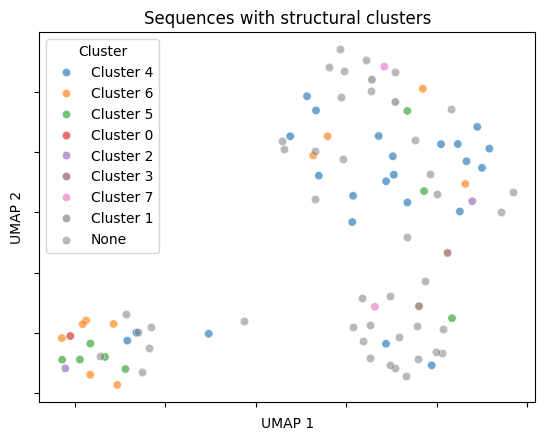

In [108]:
plot_umap(sequence_umap, dash_bmlf['structural_cluster'], title='Sequences with structural clusters')
plt.show()

## pp65 Epitope Analysis

In [109]:
dash_pp65 = dash.query("epitope == 'pp65'").copy()

In [110]:
num_tcrs = len(dash_pp65)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_a_aa'], dash.iloc[j]['cdr3_a_aa']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            dash.iloc[i]['cdr3_b_aa'], dash.iloc[j]['cdr3_b_aa']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [111]:
clusters = AgglomerativeClustering(
    n_clusters=None, distance_threshold=6, compute_full_tree=True, linkage='complete', metric='precomputed'
).fit_predict(cdr3_distance_matrix)

In [112]:
cluster_counts = {}

for cluster in clusters:
    if cluster not in cluster_counts:
        cluster_counts[cluster] = 1

    else:
        cluster_counts[cluster] += 1

cluster_order = [
    cluster
    for cluster, _ in sorted(
        sorted(cluster_counts.items(), key=lambda item: item[0]), key=lambda item: item[1], reverse=True
    )
]

In [113]:
new_order = []
for cluster in cluster_order:
    (indices,) = np.where(clusters == cluster)
    new_order.extend(indices)

new_order = np.array(new_order)

In [114]:
unique_clusters, inverse = np.unique(clusters[new_order], return_inverse=True)

palette = sns.color_palette('tab20')
num_colours = len(palette)

cluster_to_colour = {cluster: palette[i % num_colours] for i, cluster in enumerate(unique_clusters)}
cluster_colours = np.array([[cluster_to_colour[cluster]] for cluster in clusters[new_order]])

In [115]:
unique_subjects = sorted(dash_pp65['subject'].unique())
subject_to_colour = {subject: palette[i % num_colours] for i, subject in enumerate(unique_subjects)}
subject_colours = np.array([[subject_to_colour[subject]] for subject in dash_pp65['subject'].to_numpy()[new_order]])

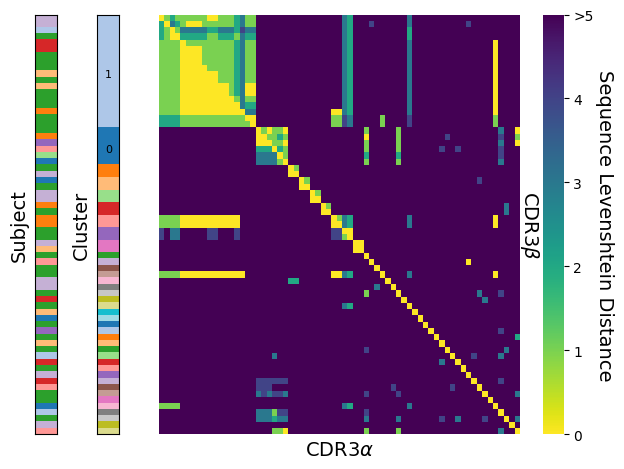

In [116]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, gridspec_kw={'width_ratios': [1, 1, 20]})

ax1.imshow(subject_colours, aspect='auto')

ax1.set_ylabel('Subject', fontsize=14)
ax1.set_xticks([])
ax1.set_xticklabels('')
ax1.set_yticks([])
ax1.set_yticklabels('')

ax2.imshow(cluster_colours, aspect='auto')

ax2.set_ylabel('Cluster', fontsize=14)
ax2.set_xticks([])
ax2.set_xticklabels('')
ax2.set_yticks([])
ax2.set_yticklabels('')

accumulation = 0
for cluster in cluster_order:
    cluster_size = cluster_counts[cluster]

    if cluster_size >= MIN_CLUSTER_SIZE:
        position = cluster_counts[cluster] // 2 + accumulation
        ax2.text(
            x=0.025,
            y=position,
            s=str(cluster),
            va='center',
            ha='center',
            fontsize=8,
        )

    accumulation += cluster_size

sns.heatmap(
    np.clip(distance_matrix[new_order, :][:, new_order], a_min=None, a_max=CLIP_DISTANCE), cmap='viridis_r', ax=ax3
)

ax3.set_xlabel(r'CDR3$\alpha$', fontsize=14)
ax3.set_ylabel(r'CDR3$\beta$', fontsize=14, rotation=270, labelpad=15)
ax3.yaxis.set_label_position('right')

ax3.set_xticks([])
ax3.set_xticklabels('')
ax3.set_yticks([])
ax3.set_yticklabels('')

cbar = ax3.collections[0].colorbar
cbar.set_label('Sequence Levenshtein Distance', fontsize=14, rotation=270, labelpad=15)
cbar.set_ticks(cbar.get_ticks())
cbar.set_ticklabels([f'{int(label)}' if label != CLIP_DISTANCE else f'>{CLIP_DISTANCE}' for label in cbar.get_ticks()])

fig.set_layout_engine('tight')

plt.show()

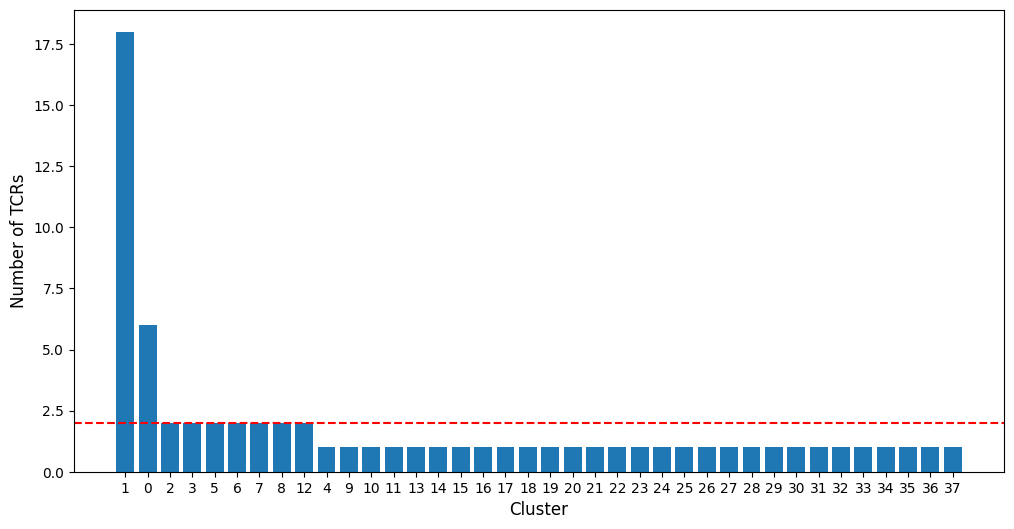

In [117]:
plt.figure(figsize=(12, 6))
plt.bar([str(cluster) for cluster in cluster_order], [cluster_counts[cluster] for cluster in cluster_order])

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of TCRs', fontsize=12)
plt.axhline(2, color='red', linestyle='--')

plt.show()

In [118]:
clusters_filtered = [cluster if cluster_counts[cluster] >= MIN_CLUSTER_SIZE else -1 for cluster in clusters]

In [119]:
dash_pp65['cluster'] = clusters_filtered
dash_pp65['cluster'] = dash_pp65['cluster'].astype(str)
dash_pp65['cluster'] = dash_pp65['cluster'].replace('-1', 'None')

In [120]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

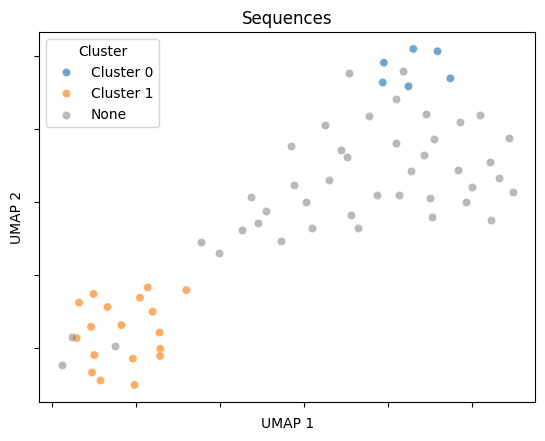

In [121]:
plot_umap(sequence_umap, dash_pp65['cluster'], title='Sequences')
plt.show()

In [122]:
sequences_with_negatives_pp65 = sequences_with_negatives.query("name == 'pp65'")

In [123]:
sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65 = sequences_with_negatives_pp65.merge(dash_pp65[['id', 'cluster']], how='left', on='id')
sequences_with_negatives_pp65['cluster'] = sequences_with_negatives_pp65['cluster'].fillna('Background')

In [124]:
num_tcrs = len(sequences_with_negatives_pp65)

cdr3_alpha_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)
cdr3_beta_distance_matrix = np.zeros((num_tcrs, num_tcrs), dtype=int)

for j in range(num_tcrs - 1):
    for i in range(j + 1, num_tcrs):
        cdr3_alpha_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_pp65.iloc[i]['cdr3_alpha'], sequences_with_negatives_pp65.iloc[j]['cdr3_alpha']
        )

for i in range(num_tcrs - 1):
    for j in range(i + 1, num_tcrs):
        cdr3_beta_distance_matrix[i, j] = damerau_levenshtein_distance(
            sequences_with_negatives_pp65.iloc[i]['cdr3_beta'], sequences_with_negatives_pp65.iloc[j]['cdr3_beta']
        )

distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_beta_distance_matrix], axis=0)

cdr3_alpha_distance_matrix = np.max([cdr3_alpha_distance_matrix, cdr3_alpha_distance_matrix.T], axis=0)
cdr3_beta_distance_matrix = np.max([cdr3_beta_distance_matrix, cdr3_beta_distance_matrix.T], axis=0)

cdr3_distance_matrix = cdr3_alpha_distance_matrix + cdr3_beta_distance_matrix

In [125]:
sequence_umap = umap.UMAP(n_jobs=1, random_state=123).fit_transform(distance_matrix)

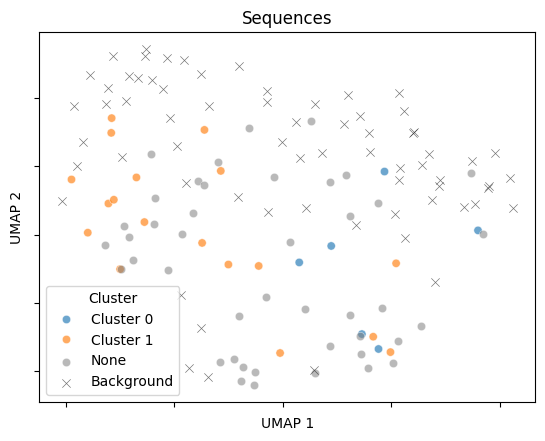

In [126]:
plot_umap(sequence_umap, sequences_with_negatives_pp65['cluster'], title='Sequences')
plt.show()